In [2]:
# 1. Setup & Imports

In [4]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, roc_auc_score, confusion_matrix,
                              classification_report, roc_curve)

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

RANDOM_STATE = 42

In [4]:
# 2. Load Data

In [5]:
df = pd.read_csv("Hotel Reservations.csv")
print("Shape:", df.shape)
df.head()

Shape: (36275, 19)


,Booking_ID,no_of_adults,no_of_children,no_of_weekend_nights,no_of_week_nights,type_of_meal_plan,required_car_parking_space,room_type_reserved,lead_time,arrival_year,arrival_month,arrival_date,market_segment_type,repeated_guest,no_of_previous_cancellations,no_of_previous_bookings_not_canceled,avg_price_per_room,no_of_special_requests,booking_status
0,INN00001,2,0,1,2,Meal Plan 1,0,Room_Type 1,224,2017,10,2,Offline,0,0,0,65.00,0,Not_Canceled
1,INN00002,2,0,2,3,Not Selected,0,Room_Type 1,5,2018,11,6,Online,0,0,0,106.68,1,Not_Canceled
2,INN00003,1,0,2,1,Meal Plan 1,0,Room_Type 1,1,2018,2,28,Online,0,0,0,60.00,0,Canceled
3,INN00004,2,0,0,2,Meal Plan 1,0,Room_Type 1,211,2018,5,20,Online,0,0,0,100.00,0,Canceled
4,INN00005,2,0,1,1,Not Selected,0,Room_Type 1,48,2018,4,11,Online,0,0,0,94.50,0,Canceled


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 36275 entries, 0 to 36274
Data columns (total 19 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   Booking_ID                            36275 non-null  object 
 1   no_of_adults                          36275 non-null  int64  
 2   no_of_children                        36275 non-null  int64  
 3   no_of_weekend_nights                  36275 non-null  int64  
 4   no_of_week_nights                     36275 non-null  int64  
 5   type_of_meal_plan                     36275 non-null  object 
 6   required_car_parking_space            36275 non-null  int64  
 7   room_type_reserved                    36275 non-null  object 
 8   lead_time                             36275 non-null  int64  
 9   arrival_year                          36275 non-null  int64  
 10  arrival_month                         36275 non-null  int64  
 11  arrival_date   

In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
no_of_adults,36275.0,1.844962,0.518715,0.0,2.0,2.00,2.0,4.0
no_of_children,36275.0,0.105279,0.402648,0.0,0.0,0.00,0.0,10.0
no_of_weekend_nights,36275.0,0.810724,0.870644,0.0,0.0,1.00,2.0,7.0
no_of_week_nights,36275.0,2.204300,1.410905,0.0,1.0,2.00,3.0,17.0
required_car_parking_space,36275.0,0.030986,0.173281,0.0,0.0,0.00,0.0,1.0
lead_time,36275.0,85.232557,85.930817,0.0,17.0,57.00,126.0,443.0
arrival_year,36275.0,2017.820427,0.383836,2017.0,2018.0,2018.00,2018.0,2018.0
arrival_month,36275.0,7.423653,3.069894,1.0,5.0,8.00,10.0,12.0
arrival_date,36275.0,15.596995,8.740447,1.0,8.0,16.00,23.0,31.0
repeated_guest,36275.0,0.025637,0.158053,0.0,0.0,0.00,0.0,1.0


In [7]:
print("Missing values per column:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())

Missing values per column:
Booking_ID                              0
no_of_adults                            0
no_of_children                          0
no_of_weekend_nights                    0
no_of_week_nights                       0
type_of_meal_plan                       0
required_car_parking_space              0
room_type_reserved                      0
lead_time                               0
arrival_year                            0
arrival_month                           0
arrival_date                            0
market_segment_type                     0
repeated_guest                          0
no_of_previous_cancellations            0
no_of_previous_bookings_not_canceled    0
avg_price_per_room                      0
no_of_special_requests                  0
booking_status                          0
dtype: int64

Duplicate rows: 0


In [ ]:
# 3. Exploratory Data Analysis

C:\Users\Swati\AppData\Local\Temp\ipykernel_19256\1931993101.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, x="booking_status", palette="Set2")


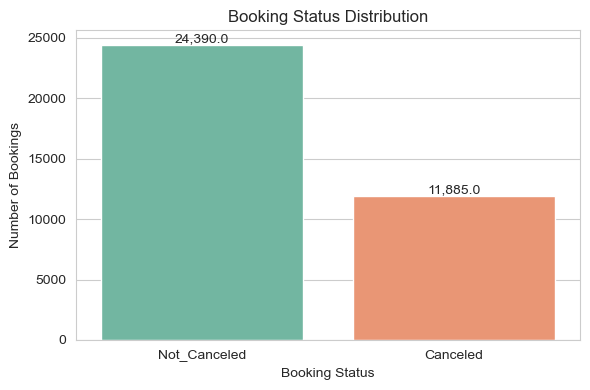

booking_status
Not_Canceled    67.2
Canceled        32.8
Name: proportion, dtype: float64 % of bookings


In [8]:
# Target distribution
plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df, x="booking_status", palette="Set2")
plt.title("Booking Status Distribution")
plt.xlabel("Booking Status")
plt.ylabel("Number of Bookings")
for p in ax.patches:
    ax.annotate(f'{p.get_height():,}', (p.get_x() + p.get_width()/2, p.get_height()),
                ha='center', va='bottom')
plt.tight_layout()
plt.show()

print(df["booking_status"].value_counts(normalize=True).round(3) * 100, "% of bookings")

C:\Users\Swati\AppData\Local\Temp\ipykernel_19256\57419967.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="booking_status", y="lead_time", palette="Set3")


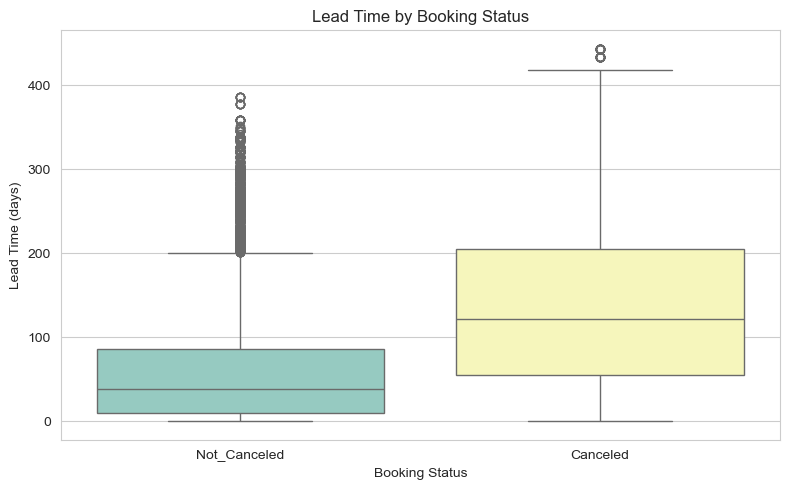

booking_status
Canceled        139.2
Not_Canceled     58.9
Name: lead_time, dtype: float64


In [9]:
# Lead time vs cancellation
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="booking_status", y="lead_time", palette="Set3")
plt.title("Lead Time by Booking Status")
plt.xlabel("Booking Status")
plt.ylabel("Lead Time (days)")
plt.tight_layout()
plt.show()

print(df.groupby("booking_status")["lead_time"].mean().round(1))

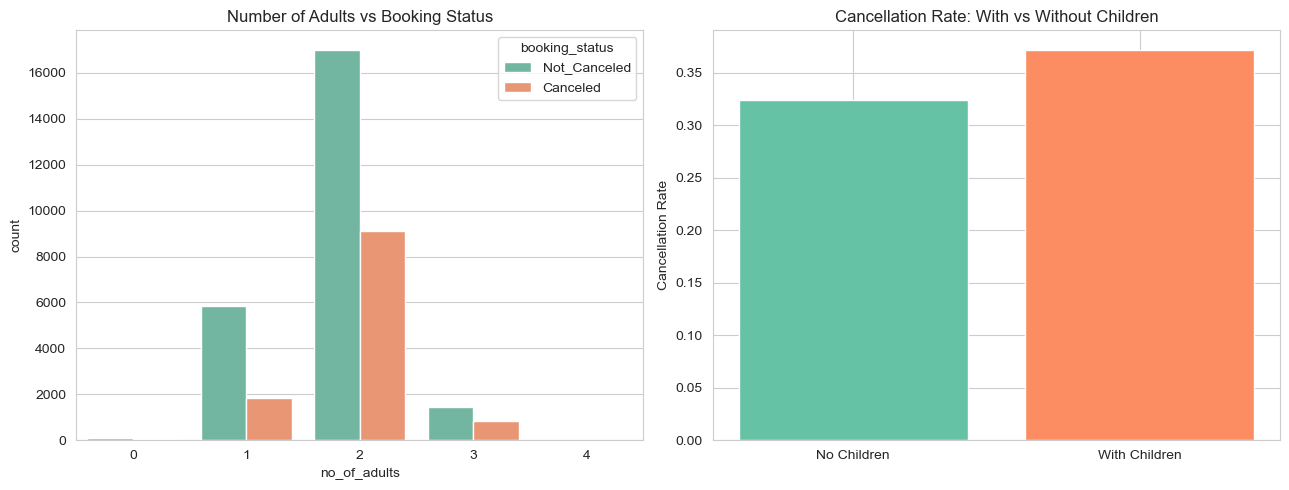

In [12]:
# Guest composition vs cancellation
df["has_children"] = (df["no_of_children"] > 0).astype(int)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.countplot(data=df, x="no_of_adults", hue="booking_status", ax=axes[0], palette="Set2")
axes[0].set_title("Number of Adults vs Booking Status")

cancel_rate_children = df.groupby("has_children")["booking_status"].apply(
    lambda x: (x == "Canceled").mean()
)
axes[1].bar(["No Children", "With Children"], cancel_rate_children.values, color=["#66c2a5", "#fc8d62"])
axes[1].set_title("Cancellation Rate: With vs Without Children")
axes[1].set_ylabel("Cancellation Rate")

plt.tight_layout()
plt.show()

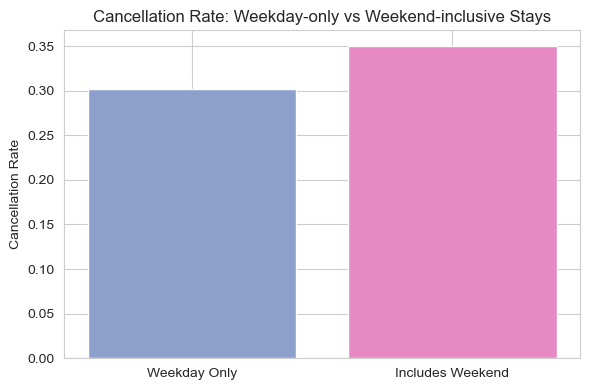

In [10]:
# Weekday vs weekend stays
df["total_nights"] = df["no_of_weekend_nights"] + df["no_of_week_nights"]
df["has_weekend_stay"] = (df["no_of_weekend_nights"] > 0).astype(int)

cancel_rate_weekend = df.groupby("has_weekend_stay")["booking_status"].apply(
    lambda x: (x == "Canceled").mean()
)

plt.figure(figsize=(6, 4))
plt.bar(["Weekday Only", "Includes Weekend"], cancel_rate_weekend.values, color=["#8da0cb", "#e78ac3"])
plt.title("Cancellation Rate: Weekday-only vs Weekend-inclusive Stays")
plt.ylabel("Cancellation Rate")
plt.tight_layout()
plt.show()

C:\Users\Swati\AppData\Local\Temp\ipykernel_19256\923203683.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=seg_cancel.index, y=seg_cancel.values, palette="viridis")


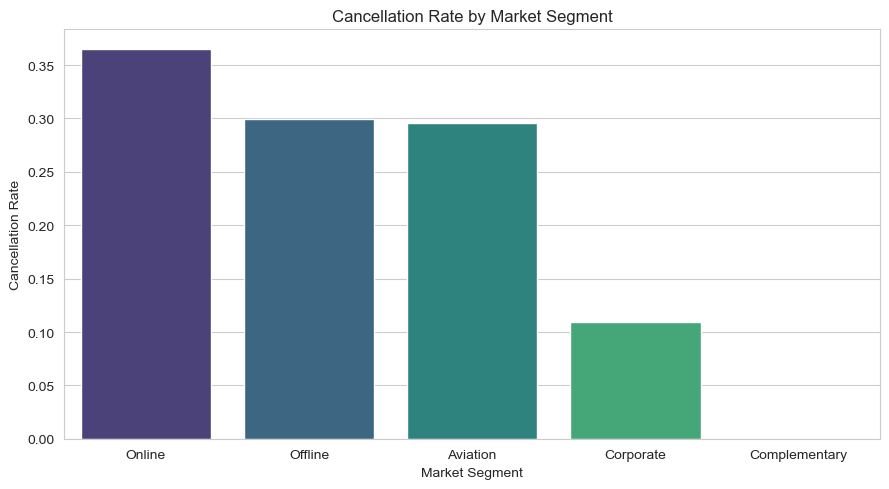

market_segment_type
Online           0.365
Offline          0.299
Aviation         0.296
Corporate        0.109
Complementary    0.000
Name: booking_status, dtype: float64


In [11]:
# Market segment vs cancellation
plt.figure(figsize=(9, 5))
seg_cancel = df.groupby("market_segment_type")["booking_status"].apply(
    lambda x: (x == "Canceled").mean()
).sort_values(ascending=False)
sns.barplot(x=seg_cancel.index, y=seg_cancel.values, palette="viridis")
plt.title("Cancellation Rate by Market Segment")
plt.ylabel("Cancellation Rate")
plt.xlabel("Market Segment")
plt.tight_layout()
plt.show()
print(seg_cancel.round(3))

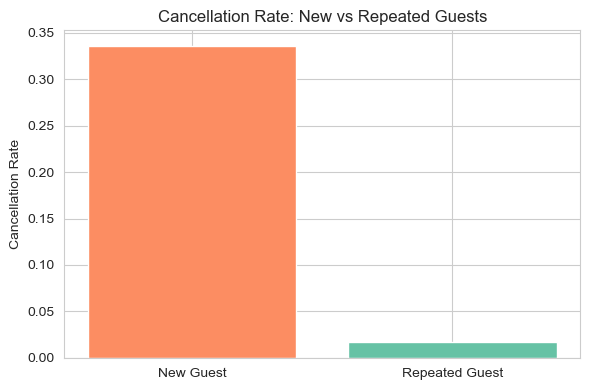

repeated_guest
0    0.336
1    0.017
Name: booking_status, dtype: float64


In [12]:
# Repeated guest vs cancellation
repeat_cancel = df.groupby("repeated_guest")["booking_status"].apply(
    lambda x: (x == "Canceled").mean()
)

plt.figure(figsize=(6, 4))
plt.bar(["New Guest", "Repeated Guest"], repeat_cancel.values, color=["#fc8d62", "#66c2a5"])
plt.title("Cancellation Rate: New vs Repeated Guests")
plt.ylabel("Cancellation Rate")
plt.tight_layout()
plt.show()
print(repeat_cancel.round(3))

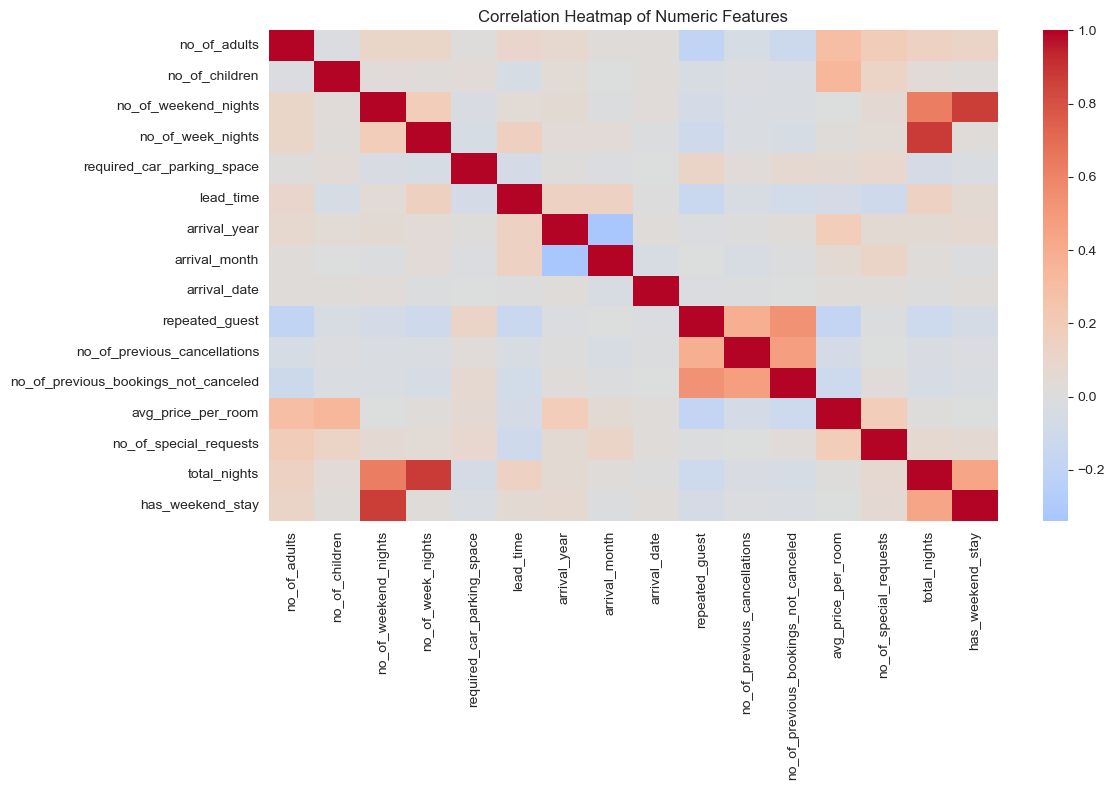

In [13]:
# Correlation heatmap
plt.figure(figsize=(12, 8))
numeric_df = df.select_dtypes(include=[np.number])
corr = numeric_df.corr()
sns.heatmap(corr, cmap="coolwarm", center=0, annot=False)
plt.title("Correlation Heatmap of Numeric Features")
plt.tight_layout()
plt.show()

In [ ]:
# 4. Preprocessing & Feature Engineering

In [14]:
model_df = df.copy()
model_df = model_df.drop(columns=["Booking_ID"])
model_df["booking_status"] = model_df["booking_status"].map({"Not_Canceled": 0, "Canceled": 1})

categorical_cols = ["type_of_meal_plan", "room_type_reserved", "market_segment_type"]
model_df = pd.get_dummies(model_df, columns=categorical_cols, drop_first=True)

print("Shape after encoding:", model_df.shape)
model_df.head()

Shape after encoding: (36275, 30)


,no_of_adults,no_of_children,no_of_weekend_nights,no_of_week_nights,required_car_parking_space,lead_time,arrival_year,arrival_month,arrival_date,repeated_guest,...,room_type_reserved_Room_Type 2,room_type_reserved_Room_Type 3,room_type_reserved_Room_Type 4,room_type_reserved_Room_Type 5,room_type_reserved_Room_Type 6,room_type_reserved_Room_Type 7,market_segment_type_Complementary,market_segment_type_Corporate,market_segment_type_Offline,market_segment_type_Online
0,2,0,1,2,0,224,2017,10,2,0,...,False,False,False,False,False,False,False,False,True,False
1,2,0,2,3,0,5,2018,11,6,0,...,False,False,False,False,False,False,False,False,False,True
2,1,0,2,1,0,1,2018,2,28,0,...,False,False,False,False,False,False,False,False,False,True
3,2,0,0,2,0,211,2018,5,20,0,...,False,False,False,False,False,False,False,False,False,True
4,2,0,1,1,0,48,2018,4,11,0,...,False,False,False,False,False,False,False,False,False,True


In [15]:
X = model_df.drop(columns=["booking_status"])
y = model_df["booking_status"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print("Train shape:", X_train.shape, " Test shape:", X_test.shape)

Train shape: (29020, 29)  Test shape: (7255, 29)


In [16]:
numeric_cols = [
    "lead_time", "avg_price_per_room",
    "no_of_previous_cancellations", "no_of_previous_bookings_not_canceled"
]

scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()
X_train_scaled[numeric_cols] = scaler.fit_transform(X_train[numeric_cols])
X_test_scaled[numeric_cols] = scaler.transform(X_test[numeric_cols])

X_train_scaled.head()

,no_of_adults,no_of_children,no_of_weekend_nights,no_of_week_nights,required_car_parking_space,lead_time,arrival_year,arrival_month,arrival_date,repeated_guest,...,room_type_reserved_Room_Type 2,room_type_reserved_Room_Type 3,room_type_reserved_Room_Type 4,room_type_reserved_Room_Type 5,room_type_reserved_Room_Type 6,room_type_reserved_Room_Type 7,market_segment_type_Complementary,market_segment_type_Corporate,market_segment_type_Offline,market_segment_type_Online
11731,2,0,2,2,0,-0.921571,2018,12,4,0,...,False,False,False,False,False,False,False,False,True,False
35609,2,0,1,4,0,0.728984,2017,12,30,0,...,False,False,False,False,False,False,False,False,True,False
21639,2,0,2,5,0,1.275294,2018,7,21,0,...,False,False,False,False,False,False,False,False,False,True
24432,1,0,0,3,0,0.089685,2018,10,6,0,...,False,False,False,False,False,False,False,False,False,True
31975,2,0,1,2,0,2.553892,2018,11,4,0,...,False,False,False,False,False,False,False,False,True,False


In [ ]:
# 5. Feature Selection

booking_status                          1.000000
lead_time                               0.438538
arrival_year                            0.179529
avg_price_per_room                      0.142569
market_segment_type_Online              0.106362
total_nights                            0.103475
no_of_week_nights                       0.092996
no_of_adults                            0.086920
type_of_meal_plan_Meal Plan 2           0.086370
no_of_weekend_nights                    0.061563
has_weekend_stay                        0.051209
no_of_children                          0.033078
room_type_reserved_Room_Type 6          0.032652
room_type_reserved_Room_Type 4          0.013309
arrival_date                            0.010629
type_of_meal_plan_Not Selected          0.003072
room_type_reserved_Room_Type 2          0.000548
room_type_reserved_Room_Type 3         -0.001241
type_of_meal_plan_Meal Plan 3          -0.003193
room_type_reserved_Room_Type 5         -0.010224
arrival_month       

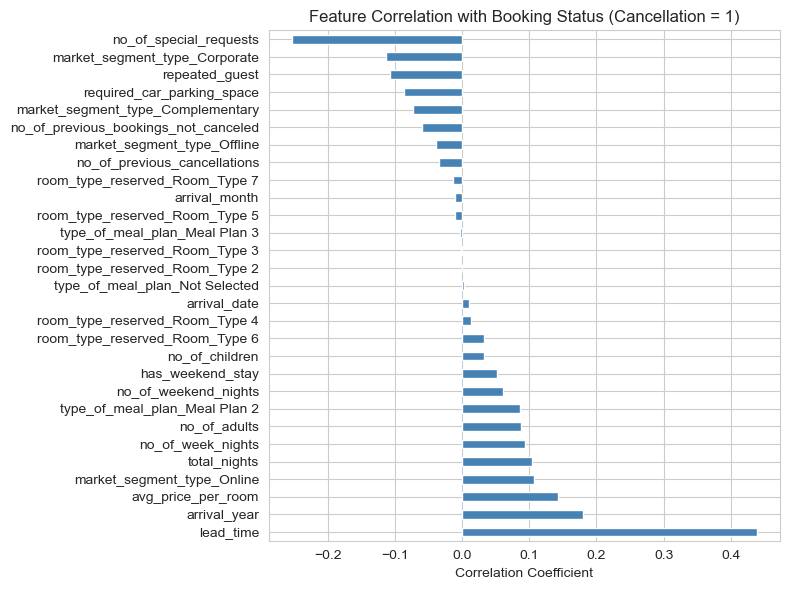

In [17]:
target_corr = model_df.corr(numeric_only=True)["booking_status"].sort_values(ascending=False)
print(target_corr)

plt.figure(figsize=(8, 6))
target_corr.drop("booking_status").plot(kind="barh", color="steelblue")
plt.title("Feature Correlation with Booking Status (Cancellation = 1)")
plt.xlabel("Correlation Coefficient")
plt.tight_layout()
plt.show()

In [ ]:
# 6. Model Training

In [18]:
# Logistic Regression
log_reg = LogisticRegression(max_iter=5000, random_state=RANDOM_STATE)
log_reg.fit(X_train_scaled, y_train)
y_pred_lr = log_reg.predict(X_test_scaled)
y_proba_lr = log_reg.predict_proba(X_test_scaled)[:, 1]

C:\Users\Swati\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [19]:
# Decision Tree
dec_tree = DecisionTreeClassifier(max_depth=10, random_state=RANDOM_STATE)
dec_tree.fit(X_train, y_train)
y_pred_dt = dec_tree.predict(X_test)
y_proba_dt = dec_tree.predict_proba(X_test)[:, 1]

In [20]:
# Random Forest
rand_forest = RandomForestClassifier(n_estimators=200, max_depth=15, random_state=RANDOM_STATE)
rand_forest.fit(X_train, y_train)
y_pred_rf = rand_forest.predict(X_test)
y_proba_rf = rand_forest.predict_proba(X_test)[:, 1]

In [ ]:
# 7. Hyperparameter Tuning (GridSearchCV)

In [ ]:
param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [10, 15, 20, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
}

grid_search = GridSearchCV(
    estimator=RandomForestClassifier(random_state=RANDOM_STATE),
    param_grid=param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1,
    verbose=1,
)

grid_search.fit(X_train, y_train)

print("Best parameters:", grid_search.best_params_)
print("Best CV F1-score: {:.4f}".format(grid_search.best_score_))

best_rf = grid_search.best_estimator_
y_pred_best_rf = best_rf.predict(X_test)
y_proba_best_rf = best_rf.predict_proba(X_test)[:, 1]

Fitting 5 folds for each of 108 candidates, totalling 540 fits


In [ ]:
# 8. Model Evaluation & Comparison

In [25]:
def evaluate_model(name, y_true, y_pred, y_proba):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1-Score": f1_score(y_true, y_pred),
        "ROC-AUC": roc_auc_score(y_true, y_proba),
    }

results = [
    evaluate_model("Logistic Regression", y_test, y_pred_lr, y_proba_lr),
    evaluate_model("Decision Tree", y_test, y_pred_dt, y_proba_dt),
    evaluate_model("Random Forest", y_test, y_pred_rf, y_proba_rf),
    evaluate_model("Random Forest (Tuned)", y_test, y_pred_best_rf, y_proba_best_rf),
]

results_df = pd.DataFrame(results).set_index("Model").round(4)
results_df

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Model,,,,,
Logistic Regression,0.8114,0.7506,0.6357,0.6884,0.8705
Decision Tree,0.8801,0.8312,0.7955,0.8130,0.9336
Random Forest,0.8973,0.8785,0.7968,0.8356,0.9532
Random Forest (Tuned),0.9049,0.8885,0.8115,0.8483,0.9569


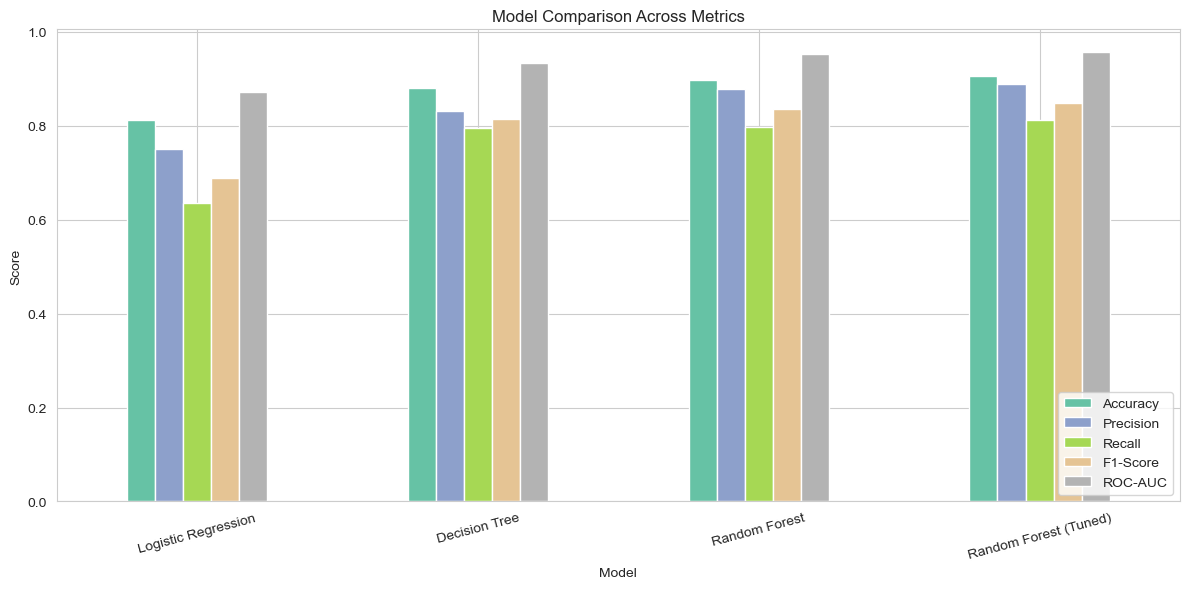

In [26]:
results_df.plot(kind="bar", figsize=(12, 6), colormap="Set2")
plt.title("Model Comparison Across Metrics")
plt.ylabel("Score")
plt.xticks(rotation=15)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

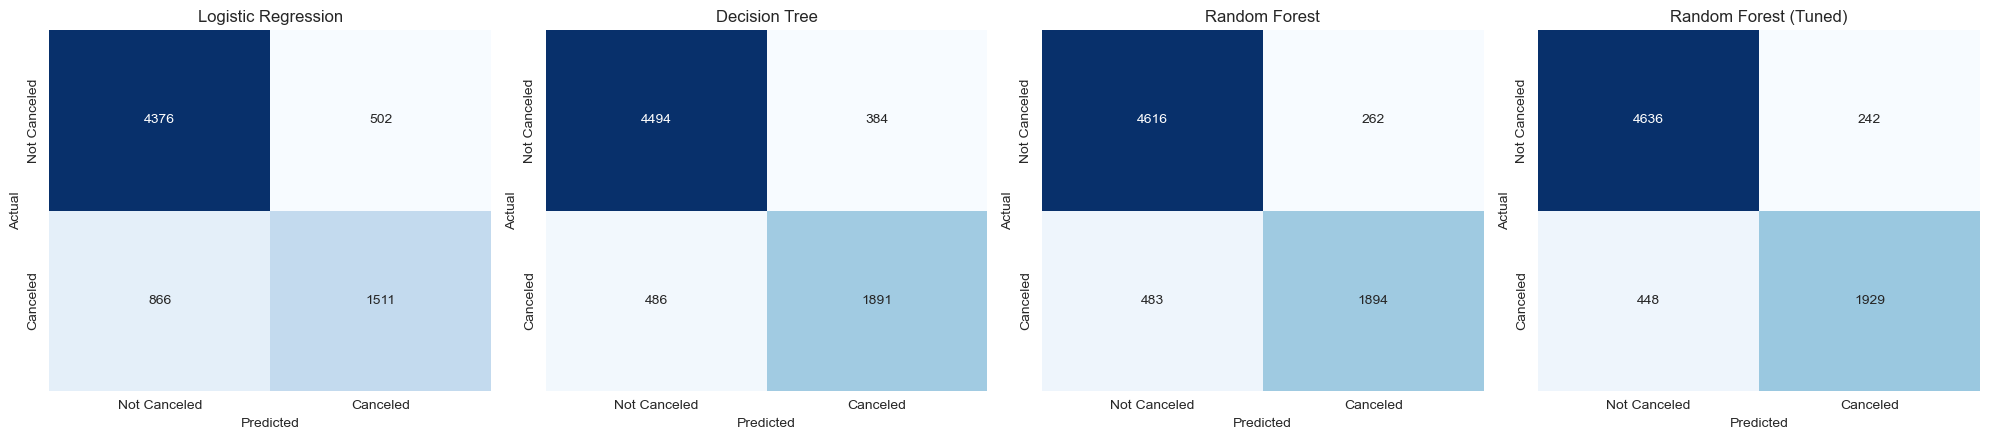

In [27]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
model_preds = {
    "Logistic Regression": y_pred_lr,
    "Decision Tree": y_pred_dt,
    "Random Forest": y_pred_rf,
    "Random Forest (Tuned)": y_pred_best_rf,
}

for ax, (name, preds) in zip(axes, model_preds.items()):
    cm = confusion_matrix(y_test, preds)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=["Not Canceled", "Canceled"],
                yticklabels=["Not Canceled", "Canceled"], ax=ax)
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

In [28]:
print("Classification Report — Random Forest (Tuned)\n")
print(classification_report(y_test, y_pred_best_rf, target_names=["Not Canceled", "Canceled"]))

Classification Report — Random Forest (Tuned)

              precision    recall  f1-score   support

Not Canceled       0.91      0.95      0.93      4878
    Canceled       0.89      0.81      0.85      2377

    accuracy                           0.90      7255
   macro avg       0.90      0.88      0.89      7255
weighted avg       0.90      0.90      0.90      7255



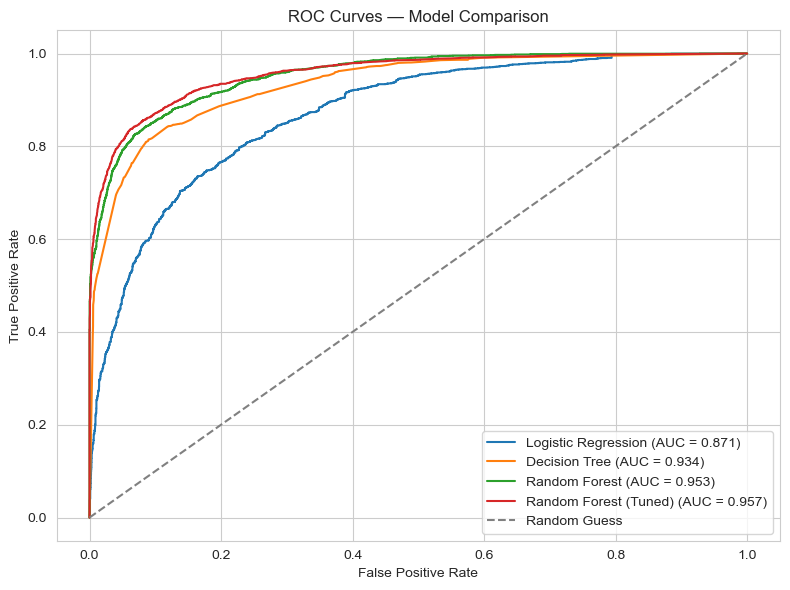

In [29]:
plt.figure(figsize=(8, 6))
for name, proba in [
    ("Logistic Regression", y_proba_lr),
    ("Decision Tree", y_proba_dt),
    ("Random Forest", y_proba_rf),
    ("Random Forest (Tuned)", y_proba_best_rf),
]:
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc = roc_auc_score(y_test, proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random Guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves — Model Comparison")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [ ]:
# 9. Feature Importance

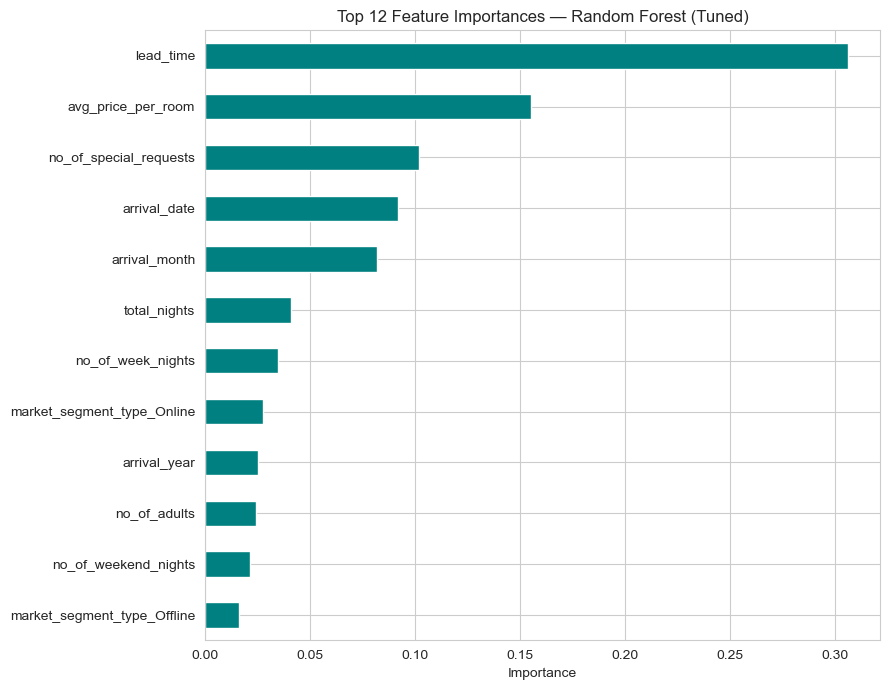

lead_time                      0.306272
avg_price_per_room             0.155447
no_of_special_requests         0.101849
arrival_date                   0.091859
arrival_month                  0.082065
total_nights                   0.041102
no_of_week_nights              0.034763
market_segment_type_Online     0.027653
arrival_year                   0.025048
no_of_adults                   0.024143
no_of_weekend_nights           0.021295
market_segment_type_Offline    0.016256
dtype: float64

In [30]:
importances = pd.Series(best_rf.feature_importances_, index=X.columns).sort_values(ascending=False)

plt.figure(figsize=(9, 7))
importances.head(12).plot(kind="barh", color="teal")
plt.gca().invert_yaxis()
plt.title("Top 12 Feature Importances — Random Forest (Tuned)")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

importances.head(12)